In [1]:
import tensorflow as tf
import sklearn
import pandas as pd
import numpy as np
from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay)
from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import matplotlib.pyplot as plt
import time


print("Library Setup Complete")

C:\Users\Raditya Prabaswara\anaconda3\envs\tf-jupyter\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Library Setup Complete


In [2]:
SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("Seed Setup Complete")

Seed Setup Complete


In [3]:
# Load Huggingface Dataset
dataset = load_dataset("SetFit/bbc-news")

print("Dataset Loaded")

Dataset Loaded


In [4]:
# Load Train Dataset
train = dataset["train"].to_pandas()

# Load Test Dataset
test = dataset["test"].to_pandas()

print("Train-Test Dataset Loaded")

Train-Test Dataset Loaded


In [5]:
print("\nMissing values:")
print(train[["text", "label"]].isnull().sum())
print(test[["text", "label"]].isnull().sum())


Missing values:
text     0
label    0
dtype: int64
text     0
label    0
dtype: int64


### Mapping Label
0 : tech

1 : business

2 : sport

3 : entertainment

4 : politics

In [6]:
print("\nTraining label mapping:")
print(
    train[["label", "label_text"]]
    .drop_duplicates()
    .sort_values("label")
)


Training label mapping:
   label     label_text
4      0           tech
1      1       business
0      2          sport
2      3  entertainment
5      4       politics


In [7]:
# Validation Split
X = train["text"].to_numpy()
y = train["label"].to_numpy()

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=SEED,
    stratify=y
)

X_test = test["text"].to_numpy()
y_test = test["label"].to_numpy()

print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))

Training: 980
Validation: 245
Testing: 1000


In [8]:
MAX_WORDS = 10000
MAX_LEN = 300

tokenizer = tf.keras.preprocessing.text.Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_val_seq = tokenizer.texts_to_sequences(X_val)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_pad = tf.keras.preprocessing.sequence.pad_sequences(
    X_train_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_val_pad = tf.keras.preprocessing.sequence.pad_sequences(
    X_val_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_test_pad = tf.keras.preprocessing.sequence.pad_sequences(
    X_test_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

print("Training input shape:", X_train_pad.shape)
print("Validation input shape:", X_val_pad.shape)
print("Test input shape:", X_test_pad.shape)
print("Vocabulary size:", min(len(tokenizer.word_index) + 1, MAX_WORDS))

Training input shape: (980, 300)
Validation input shape: (245, 300)
Test input shape: (1000, 300)
Vocabulary size: 10000


In [9]:
NUM_CLASSES = train["label"].nunique()

print("Number of classes:", NUM_CLASSES)
print("Training labels:", np.unique(y_train))
print("Test labels:", np.unique(y_test))

Number of classes: 5
Training labels: [0 1 2 3 4]
Test labels: [0 1 2 3 4]


In [10]:
print("RNN + Transformer + LDA Start")

RNN + Transformer + LDA Start


In [11]:
# Jumlah topik yang ingin ditemukan
N_TOPICS = 5

# Ubah teks menjadi representasi frekuensi kata
lda_vectorizer = CountVectorizer(
    max_features=10000,
    stop_words="english",
    max_df=0.95,
    min_df=2
)

X_train_bow = lda_vectorizer.fit_transform(X_train)

# Training LDA
lda_model = LatentDirichletAllocation(
    n_components=N_TOPICS,
    random_state=SEED,
    max_iter=10,
    learning_method="batch"
)

lda_model.fit(X_train_bow)

print("LDA Training Complete")
print("Document-term matrix:", X_train_bow.shape)

LDA Training Complete
Document-term matrix: (980, 10000)


In [12]:
feature_names = lda_vectorizer.get_feature_names_out()

for topic_idx, topic in enumerate(lda_model.components_):
    top_indices = topic.argsort()[-10:][::-1]
    top_words = [feature_names[i] for i in top_indices]

    print(f"\nTopic {topic_idx + 1}:")
    print(", ".join(top_words))


Topic 1:
said, year, people, film, best, music, new, uk, tv, market

Topic 2:
said, year, world, win, time, final, won, team, cup, old

Topic 3:
said, half, game, new, china, time, computer, security, ireland, liverpool

Topic 4:
said, mr, government, labour, people, election, party, new, blair, minister

Topic 5:
said, year, company, sales, england, oil, firm, search, yukos, court


In [13]:
# Distribusi topik setiap dokumen
lda_train_features = lda_model.transform(X_train_bow)

# Transformasi validation dan test menggunakan LDA yang sama
X_val_bow = lda_vectorizer.transform(X_val)
X_test_bow = lda_vectorizer.transform(X_test)

lda_val_features = lda_model.transform(X_val_bow)
lda_test_features = lda_model.transform(X_test_bow)

print("Train topic features:", lda_train_features.shape)
print("Validation topic features:", lda_val_features.shape)
print("Test topic features:", lda_test_features.shape)

# Contoh distribusi topik untuk satu berita
print("\nTopic distribution for first training article:")
print(np.round(lda_train_features[0], 3))

Train topic features: (980, 5)
Validation topic features: (245, 5)
Test topic features: (1000, 5)

Topic distribution for first training article:
[0.77  0.001 0.001 0.226 0.001]


In [14]:
label_encoder = LabelEncoder()

y_train_enc = label_encoder.fit_transform(y_train)
y_val_enc = label_encoder.transform(y_val)
y_test_enc = label_encoder.transform(y_test)

NUM_CLASSES = len(label_encoder.classes_)

print("Number of classes:", NUM_CLASSES)
print("Label mapping:")

for i, label in enumerate(label_encoder.classes_):
    print(f"{label} -> {i}")

Number of classes: 5
Label mapping:
0 -> 0
1 -> 1
2 -> 2
3 -> 3
4 -> 4


In [15]:
# Hyperparameters
EMBED_DIM = 128
LSTM_UNITS = 64
NUM_HEADS = 4
FF_DIM = 128
DROPOUT = 0.3

# Input teks
text_input = layers.Input(
    shape=(MAX_LEN,),
    dtype="int32",
    name="text_input"
)

# Word embedding
x = layers.Embedding(
    input_dim=MAX_WORDS,
    output_dim=EMBED_DIM,
    mask_zero=True,
    name="word_embedding"
)(text_input)

# Positional embedding
position_ids = tf.range(start=0, limit=MAX_LEN, delta=1)

position_embedding_layer = layers.Embedding(
    input_dim=MAX_LEN,
    output_dim=EMBED_DIM,
    name="position_embedding"
)

position_embeddings = position_embedding_layer(position_ids)

# Explicitly add batch dimension:
# (300, 128) -> (1, 300, 128)
position_embeddings = layers.Lambda(
    lambda t: tf.expand_dims(t, axis=0),
    output_shape=(1, MAX_LEN, EMBED_DIM),
    name="add_position_batch_dimension"
)(position_embeddings)

# Combine word and positional embeddings
x = layers.Add(name="embedding_plus_position")([
    x,
    position_embeddings
])

# RNN: SimpleRNN
x = layers.SimpleRNN(
    128,
    return_sequences=True,
    dropout=0.2,
    name="simple_rnn"
)(x)

# Transformer Encoder: Self-Attention
attention_output = layers.MultiHeadAttention(
    num_heads=NUM_HEADS,
    key_dim=EMBED_DIM // NUM_HEADS,
    dropout=DROPOUT,
    name="multihead_attention"
)(
    query=x,
    value=x,
    key=x
)

# Residual connection + normalization
x = layers.Add()([x, attention_output])
x = layers.LayerNormalization(epsilon=1e-6)(x)

# Feed-forward network
ffn = layers.Dense(
    FF_DIM,
    activation="relu"
)(x)

ffn = layers.Dropout(DROPOUT)(ffn)

ffn = layers.Dense(
    EMBED_DIM,
    activation="linear"
)(ffn)

# Residual connection + normalization
x = layers.Add()([x, ffn])
x = layers.LayerNormalization(epsilon=1e-6)(x)

# Global pooling
text_features = layers.GlobalAveragePooling1D()(x)
text_features = layers.Dropout(DROPOUT)(text_features)

# LDA input
lda_input = layers.Input(
    shape=(N_TOPICS,),
    dtype="float32",
    name="lda_input"
)

lda_features = layers.Dense(
    32,
    activation="relu"
)(lda_input)

# Combine text and LDA features
combined = layers.Concatenate()([
    text_features,
    lda_features
])

combined = layers.Dense(
    64,
    activation="relu"
)(combined)

combined = layers.Dropout(DROPOUT)(combined)

# Classification output
output = layers.Dense(
    NUM_CLASSES,
    activation="softmax",
    name="classification"
)(combined)

model = Model(
    inputs=[text_input, lda_input],
    outputs=output,
    name="SimpleRNN_Transformer_LDA"
)

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "SimpleRNN_Transformer_LDA"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ text_input (InputLayer)       │ (None, 300)               │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ word_embedding (Embedding)    │ (None, 300, 128)          │       1,280,000 │ text_input[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ embedding_plus_position (Add) │ (1, 300, 128)             │               0 │ word_embedding[0][0]       │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ simple_rnn (SimpleRNN)        │ (1, 300, 128)             │          32,896 │ embedding_plus_position[0… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ multihead_attention           │ (1, 300, 128)             │          66,048 │ simple_rnn[0][0],          │
│ (MultiHeadAttention)          │                           │                 │ simple_rnn[0][0],          │
│                               │                           │                 │ simple_rnn[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add (Add)                     │ (1, 300, 128)             │               0 │ simple_rnn[0][0],          │
│                               │                           │                 │ multihead_attention[0][0]  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ layer_normalization           │ (1, 300, 128)             │             256 │ add[0][0]                  │
│ (LayerNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense (Dense)                 │ (1, 300, 128)             │          16,512 │ layer_normalization[0][0]  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dropout_1 (Dropout)           │ (1, 300, 128)             │               0 │ dense[0][0]                │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_1 (Dense)               │ (1, 300, 128)             │          16,512 │ dropout_1[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add_1 (Add)                   │ (1, 300, 128)             │               0 │ layer_normalization[0][0], │
│                               │                           │                 │ dense_1[0][0]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ layer_normalization_1         │ (1, 300, 128)             │             256 │ add_1[0][0]                │
│ (LayerNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ global_average_pooling1d      │ (1, 128)                  │               0 │ layer_normalization_1[0][… │
│ (GlobalAveragePooling1D)      │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ lda_input (InputLayer)        │ (None, 5)                 │               

 Total params: 1,423,301 (5.43 MB)

 Trainable params: 1,423,301 (5.43 MB)

 Non-trainable params: 0 (0.00 B)

In [16]:
print("Model input shapes:", model.input_shape)
print("Model output shape:", model.output_shape)

for layer in model.layers:
    if layer.name in [
        "word_embedding",
        "position_embedding",
        "add_position_batch_dimension",
        "embedding_plus_position"
    ]:
        print(layer.name, layer.output.shape)

Model input shapes: [(None, 300), (None, 5)]
Model output shape: (1, 5)
word_embedding (None, 300, 128)
embedding_plus_position (1, 300, 128)


In [17]:
# Early Stopping
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

# Start timer
start_time = time.time()

# Train RNN + Transformer + LDA model
history = model.fit(
    x={
        "text_input": X_train_pad,
        "lda_input": lda_train_features
    },
    y=y_train_enc,
    validation_data=(
        {
            "text_input": X_val_pad,
            "lda_input": lda_val_features
        },
        y_val_enc
    ),
    epochs=15,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

# Calculate training duration
end_time = time.time()
training_time = end_time - start_time

print("Training Complete")
print(f"Training Time: {training_time:.2f} seconds")
print(f"Training Time: {training_time / 60:.2f} minutes")

Epoch 1/15
31/31 ━━━━━━━━━━━━━━━━━━━━ 76s 712ms/step - accuracy: 0.3980 - loss: 1.3793 - val_accuracy: 0.6245 - val_loss: 0.9380
Epoch 2/15
31/31 ━━━━━━━━━━━━━━━━━━━━ 17s 538ms/step - accuracy: 0.7541 - loss: 0.6630 - val_accuracy: 0.8612 - val_loss: 0.3958
Epoch 3/15
31/31 ━━━━━━━━━━━━━━━━━━━━ 17s 555ms/step - accuracy: 0.9143 - loss: 0.2697 - val_accuracy: 0.9020 - val_loss: 0.3250
Epoch 4/15
31/31 ━━━━━━━━━━━━━━━━━━━━ 11s 360ms/step - accuracy: 0.9694 - loss: 0.1124 - val_accuracy: 0.9347 - val_loss: 0.2364
Epoch 5/15
31/31 ━━━━━━━━━━━━━━━━━━━━ 10s 315ms/step - accuracy: 0.9898 - loss: 0.0338 - val_accuracy: 0.9429 - val_loss: 0.2126
Epoch 6/15
31/31 ━━━━━━━━━━━━━━━━━━━━ 10s 330ms/step - accuracy: 0.9908 - loss: 0.0276 - val_accuracy: 0.9510 - val_loss: 0.1647
Epoch 7/15
31/31 ━━━━━━━━━━━━━━━━━━━━ 8s 262ms/step - accuracy: 0.9918 - loss: 0.0237 - val_accuracy: 0.9388 - val_loss: 0.2761
Epoch 8/15
31/31 ━━━━━━━━━━━━━━━━━━━━ 8s 259ms/step - accuracy: 0.9918 - loss: 0.0299 - val_accura

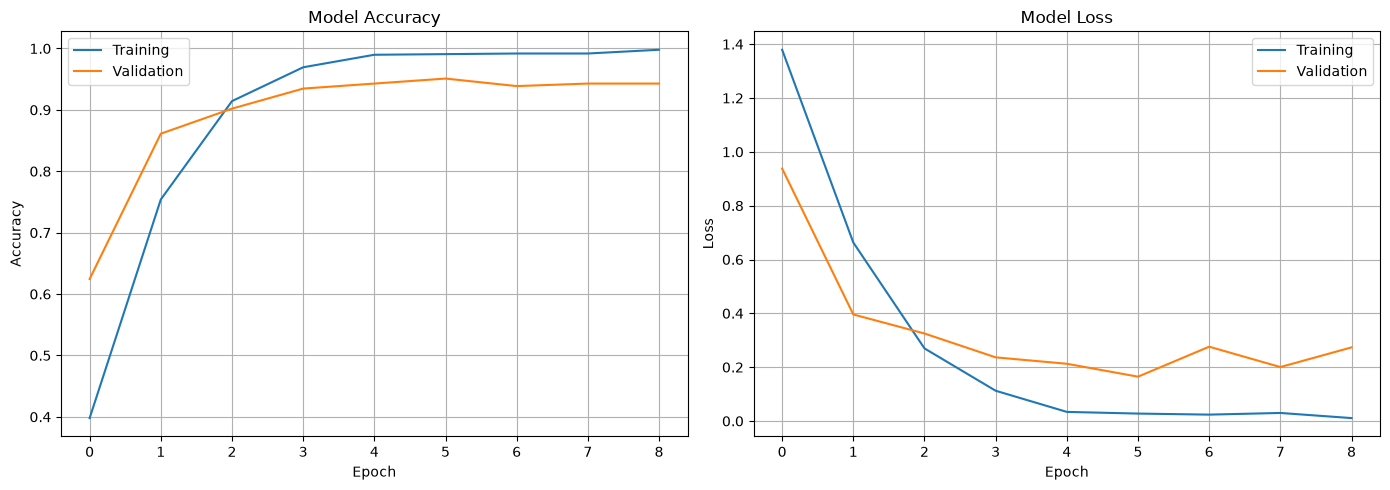

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
axes[0].plot(history.history["accuracy"], label="Training")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("Model Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

# Loss
axes[1].plot(history.history["loss"], label="Training")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("Model Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [19]:
# Evaluasi loss dan accuracy
test_loss, test_accuracy = model.evaluate(
    {
        "text_input": X_test_pad,
        "lda_input": lda_test_features
    },
    y_test_enc,
    verbose=1
)

# Prediksi kelas
y_prob = model.predict(
    {
        "text_input": X_test_pad,
        "lda_input": lda_test_features
    },
    verbose=1
)

y_pred = np.argmax(y_prob, axis=1)

print(f"\nTest Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test_enc,
        y_pred,
        labels=np.arange(NUM_CLASSES),
        target_names=[str(label) for label in label_encoder.classes_],
        zero_division=0
    )
)

32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 55ms/step - accuracy: 0.9410 - loss: 0.2363
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 107ms/step

Test Loss     : 0.2363
Test Accuracy : 0.9410

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.94      0.95       189
           1       0.93      0.92      0.92       224
           2       0.94      1.00      0.97       236
           3       0.94      0.91      0.93       176
           4       0.94      0.93      0.93       175

    accuracy                           0.94      1000
   macro avg       0.94      0.94      0.94      1000
weighted avg       0.94      0.94      0.94      1000



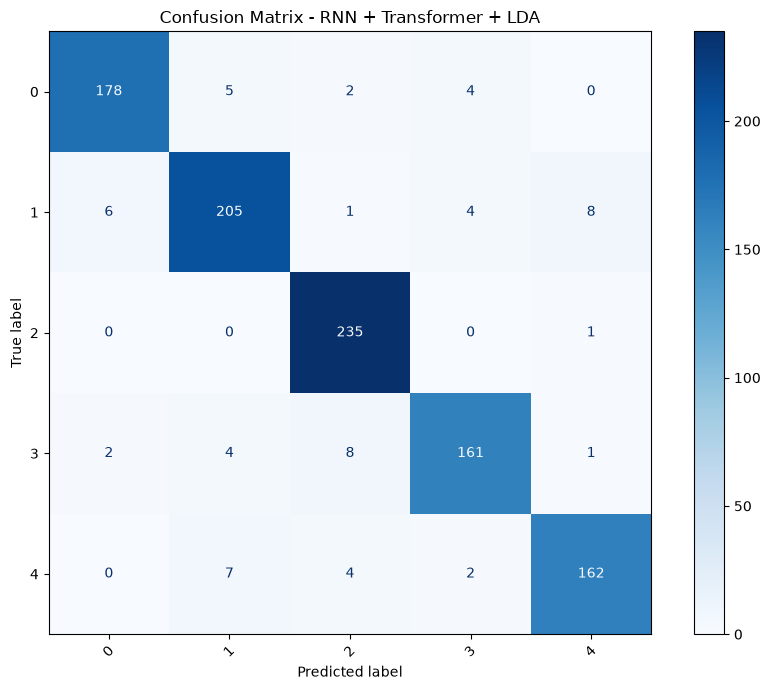

In [20]:
cm = confusion_matrix(
    y_test_enc,
    y_pred,
    labels=np.arange(NUM_CLASSES)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
)

fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d"
)

plt.title("Confusion Matrix - RNN + Transformer + LDA")
plt.tight_layout()
plt.show()

In [21]:
def predict_news(text):
    # Tokenisasi
    sequence = tokenizer.texts_to_sequences([text])

    padded = tf.keras.preprocessing.sequence.pad_sequences(
        sequence,
        maxlen=MAX_LEN,
        padding="post",
        truncating="post"
    )

    # Distribusi topik LDA
    bow = lda_vectorizer.transform([text])
    topic_features = lda_model.transform(bow)

    # Prediksi
    probabilities = model.predict(
        {
            "text_input": padded,
            "lda_input": topic_features
        },
        verbose=0
    )[0]

    predicted_index = np.argmax(probabilities)
    predicted_label = label_encoder.inverse_transform(
        [predicted_index]
    )[0]

    print("Predicted category:", predicted_label)
    print(f"Confidence: {probabilities[predicted_index]:.2%}")

    # Distribusi probabilitas seluruh kelas
    print("\nClass probabilities:")
    for i, label in enumerate(label_encoder.classes_):
        print(f"{label}: {probabilities[i]:.2%}")

    # Distribusi topik
    print("\nLDA topic distribution:")
    for i, probability in enumerate(topic_features[0]):
        print(f"Topic {i + 1}: {probability:.2%}")

    return predicted_label


# Contoh penggunaan
sample_news = """
The government announced new economic policies to support
businesses and increase employment across the country.
"""

predicted_category = predict_news(sample_news)

Predicted category: 4
Confidence: 84.03%

Class probabilities:
0: 0.00%
1: 15.66%
2: 0.30%
3: 0.01%
4: 84.03%

LDA topic distribution:
Topic 1: 1.83%
Topic 2: 1.82%
Topic 3: 1.83%
Topic 4: 92.68%
Topic 5: 1.84%


In [22]:
# Save model after training
model.save("simplernn_transformer_lda_model.keras")

print("RNN + Transformer + LDA model saved successfully!")

RNN + Transformer + LDA model saved successfully!
